In [1]:

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from alpha_beta_complex import (compute_symmetry_index, alpha_beta_ratio, compute_tfr, compute_psd)
import random
import pandas as pd
import os
import os.path as op
import numpy as np
import pickle

import scipy.io as sio

from hnn_core import duecker_ET_model, simulate_dipole, MPIBackend

pathfig = '/users/kduecker/hnn-tuning/new_model_HNN/figures/alpha_beta'

os.makedirs(pathfig, exist_ok=True)

main_pth = '/users/kduecker/hnn-tuning/new_model_HNN/alpha_beta/'
data_pth = '/users/kduecker/SpectralEvents/data'
out_pth = op.join(main_pth, 'sim_results')
path_fig = op.join(out_pth, 'figures')
os.makedirs(out_pth, exist_ok=True)
os.makedirs(path_fig, exist_ok=True)


import time
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
n_procs = 60

--No graphics will be displayed.


In [2]:
import os

# Use conda's newer libstdc++ instead of the system one
conda_lib = os.path.expanduser("~/.conda/envs/hnn-core-env/lib")
ld_path = os.environ.get("LD_LIBRARY_PATH", "")
os.environ["LD_LIBRARY_PATH"] = f"{conda_lib}:{ld_path}"

# UCX settings (from before)
os.environ["UCX_TLS"] = "tcp,self,sm"
os.environ["UCX_NET_DEVICES"] = "all"


# MPI paths
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
mpi_lib = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/lib"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"
if mpi_lib not in ld_path:
    os.environ["LD_LIBRARY_PATH"] = f"{mpi_lib}:{os.environ['LD_LIBRARY_PATH']}"

import sys
# Add MPI bin directory to PATH
mpi_bin = "/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin"
if mpi_bin not in os.environ["PATH"]:
    os.environ["PATH"] = f"{mpi_bin}:{os.environ['PATH']}"

print("Updated PATH to include MPI")
print("MPI location:", mpi_bin)

import os
print("PATH:", os.environ.get('PATH', 'NOT SET'))
print("Which mpiexec:")
import subprocess
result = subprocess.run(['which', 'mpiexec'], capture_output=True, text=True)
print(result.stdout if result.returncode == 0 else "mpiexec not found")

Updated PATH to include MPI
MPI location: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin
PATH: /oscar/rt/sw/external/hpcx-mpi/2.25.1/bin:/users/kduecker/.conda/envs/hnn-core-env/bin:/oscar/rt/9.6/25/x86_64_v3/code-server-4.96.4-2mbqypo7726gva5cbeogfppy2doijdhq/lib/vscode/bin/remote-cli:/users/kduecker/bin:/oscar/runtime/bin:/oscar/rt/9.6/25/spack/x86_64_v3/code-server-4.96.4-2mbqypo7726gva5cbeogfppy2doijdhq/bin:/users/kduecker/.conda/envs/hnn-core-env/bin:/oscar/rt/9.6/25/x86_64_v3/miniforge3-25.3.0-3-a6hhdjzejtacz63sugjqnvgosfqz63ul/condabin:/users/kduecker/bin:/usr/local/bin:/usr/bin:/usr/local/sbin:/usr/sbin:/usr/lpp/mmfs/bin:/usr/lpp/mmfs/sbin:/users/kduecker/bin
Which mpiexec:
/oscar/rt/sw/external/hpcx-mpi/2.25.1/bin/mpiexec



In [3]:
import os.path as op
out_pth = '/users/kduecker/hnn-tuning/new_model_HNN/alpha_beta/sim_results/'



In [4]:
fb_delay = 5
run_idx = 1
netfilename = op.join(out_pth, f'net_delay_{fb_delay}ms_fb_std_15_{run_idx}.pkl')
dplfilename = op.join(out_pth, f'dpl_delay_{fb_delay}ms_fb_std_15_{run_idx}.pkl')

with open(netfilename, 'rb') as file:
    net = pickle.load(file) #



In [5]:
with open(op.join(out_pth, f'alpha_beta_complex_simulation_delay_{fb_delay}ms_fb_std_15_1.pkl'), 'rb') as f:
   sim = pickle.load(f)

with open(dplfilename, 'rb') as file:
    dpl = pickle.load(file)

In [6]:
from alpha_beta_complex import run_alpha_beta_complex_simulations, compute_tfr, sim_analysis_params_default

params = sim_analysis_params_default()
# params['n_procs']= n_procs
# params['prox_seed'] = 544
# params['dist_seed'] = 476
# dpl, net = run_alpha_beta_complex_simulations(params, n_trials=600)

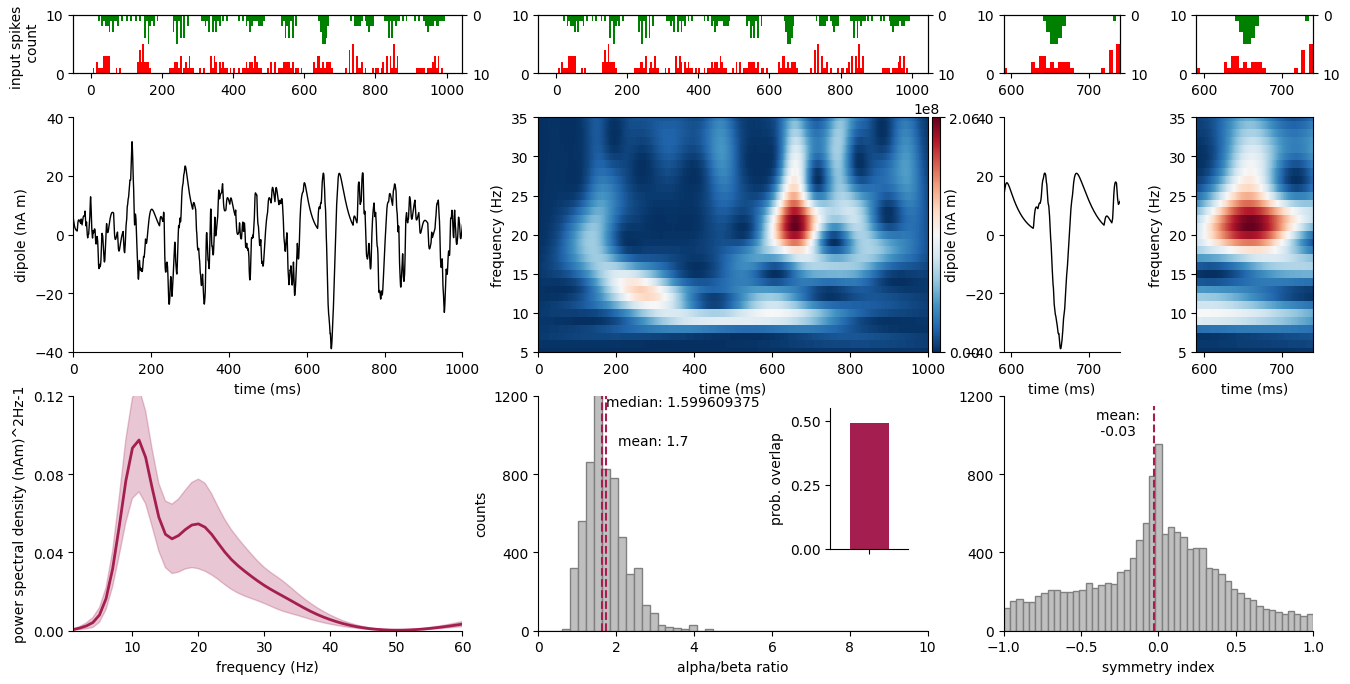

In [7]:
fig = plt.figure(figsize=(16,8))
gs= GridSpec(3, 4, width_ratios=[1,1,0.3, 0.3], height_ratios=[0.25, 1, 1], wspace=.3, hspace=0.25)
bins = np.arange(0, 1000, 5)  # histogram bins

ax = [None]*11
ax[0] = fig.add_subplot(gs[0,0])
ax[1] = fig.add_subplot(gs[0,1])
ax[2] = fig.add_subplot(gs[0,2])
ax[3] = fig.add_subplot(gs[0,3])

ax[4] = fig.add_subplot(gs[1,0])
ax[5] = fig.add_subplot(gs[1,1])
ax[6] = fig.add_subplot(gs[1,2])
ax[7] = fig.add_subplot(gs[1,3])

ax[8] = fig.add_subplot(gs[2,0])
ax[9] = fig.add_subplot(gs[2,1])
ax[10] = fig.add_subplot(gs[2,2:])
#fig.tight_layout()
fig.canvas.draw()

spike_prox = np.array(net.cell_response.spike_times_by_type['prox'][0]).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['dist'][0]).reshape(-1,1)

for i in range(4):
    ax[i].hist(spike_prox, bins, color='r')
    ax[i].set_ylim([0, 10])
    ax[i].set_yticks([0, 10])

    ax1tw = ax[i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 10])
    ax1tw.set_yticks([0, 10])
    ax1tw.invert_yaxis()

ax[0].set_ylabel('input spikes \n count')
ax[4].plot(dpl[0].times, dpl[0].data['agg'], color='k', linewidth=1.)
ax[4].set_yticks([-40, -20, 0, 20, 40])

ax[4].set_xlim([0, 1000])
ax[4].spines['top'].set_visible(False)
ax[4].spines['right'].set_visible(False)
ax[4].set_ylabel('dipole (nA m)')
ax[4].set_ylim([-40, 40])
f, tfr = compute_tfr([dpl[0]])

im = ax[5].pcolormesh(dpl[0].times, f, tfr[0], cmap='RdBu_r', vmin=0, vmax=tfr.max())
# Get the position of ax[3] in figure coordinates
pos = ax[5].get_position()
# Create a new axes for the colorbar just to the right of ax[3]
cax = fig.add_axes([pos.x1 + 0.0025, pos.y0, 0.005, pos.height])
#cax.set_axis_off()
cb = plt.colorbar(im, cax=cax)
cb.set_ticks([0, tfr.max()])
ax[5].set_ylim([5, 35])
ax[5].set_ylabel('frequency (Hz)')
ax[6].plot(dpl[0].times, dpl[0].data['agg'], color='k', linewidth=1.)
ax[6].set_xlim([590, 740])
ax[6].spines['top'].set_visible(False)
ax[6].spines['right'].set_visible(False)
ax[6].set_ylabel('dipole (nA m)')
ax[6].set_ylim([-40, 40])
ax[6].set_yticks([-40, -20, 0, 20, 40])
ax[7].pcolormesh(dpl[0].times, f, tfr[0], cmap='RdBu_r')
ax[7].set_ylim([5, 35])
ax[7].set_ylabel('frequency (Hz)')

ax[7].set_xlim([590, 740])
ax[2].set_xlim([590, 740])
ax[3].set_xlim([590, 740])

for i in np.arange(4,8):
    ax[i].set_xlabel('time (ms)')


f, psd = compute_psd(params, dpl)

ax[8].plot(f[0], psd.mean(axis=0),color='#a41f50', linewidth=2)
ax[8].set_xlim([1, 60])
ax[8].fill_between(f[0], psd.mean(axis=0)-psd.std(axis=0), psd.mean(axis=0)+psd.std(axis=0),color='#a41f50', alpha=0.25)
ax[8].spines['top'].set_visible(False)
ax[8].spines['right'].set_visible(False)
ax[8].set_ylabel('power spectral density (nAm)^2Hz-1')
ax[8].set_ylim([0, 0.12])
ax[8].set_yticks([0, 0.04, 0.08, 0.12])
ax[8].set_xlabel('frequency (Hz)')

abr = np.concatenate(sim.alpha_beta_ratio.values)
mabr = np.round(np.mean(abr),1).astype('float16')
medabr = np.round(np.median(abr),1).astype('float16')
ax[9].hist(abr, bins=np.linspace(0, 10, 50), facecolor=[0.75, 0.75, 0.75], edgecolor=[0.5, 0.5, 0.5]);
ax[9].vlines(np.mean(abr), ymin=0, ymax=1200, color='#a41f50', linestyle='--')
ax[9].vlines(np.median(abr), ymin=0, ymax=1200, color='#a41f50', linestyle='--')
ax[9].text(np.mean(abr)+0.3, 950, f'mean: {mabr:0.1f}', color='k')
ax[9].text(np.median(abr)+0.1, 1150, f'median: {medabr}', color='k')
ax[9].set_xlabel('alpha/beta ratio')
ax[9].spines['top'].set_visible(False)
ax[9].spines['right'].set_visible(False)
ax[9].set_ylim([0, 1200])
ax[9].set_yticks([0, 400, 800, 1200])
ax[9].set_xlim([0, 10])
ax92 = ax[9].inset_axes([.75, 0.35, 0.2, .6])
ax92.bar(x=1, height=np.mean(sim.prob_overlap), width=0.5, color='#a41f50')
ax92.set_xlim([0.5, 1.5])
ax92.set_xticks([1])
ax92.set_xticklabels([])
ax92.set_ylim([0, 0.55])
ax92.set_yticks([0, 0.25, 0.5])
ax92.set_ylabel('prob. overlap')
ax92.spines['top'].set_visible(False)
ax92.spines['right'].set_visible(False)
ax[9].set_ylabel('counts')

sid = np.concatenate(sim.symmetry_index.values)
ax[10].hist(sid, bins=np.linspace(-1,1,50), facecolor=[0.75, 0.75, 0.75], edgecolor=[0.5, 0.5, 0.5]);
ax[10].vlines(np.mean(sid), ymin=0, ymax=1150, linewidth=1.5, color='#a41f50', linestyle='--')
ax[10].text(-0.4, 1000, f'mean: \n {np.round(np.mean(sid),2)}')
ax[10].set_xlabel('symmetry index')
ax[10].spines['top'].set_visible(False)
ax[10].spines['right'].set_visible(False)
ax[10].set_ylim([0, 1200])
ax[10].set_yticks(np.arange(0, 1201, 400))
ax[10].set_xlim([-1, 1])

fig.savefig(op.join(pathfig, 'alpha_beta_sim.pdf'))
fig.savefig(op.join(pathfig, 'alpha_beta_sim.png'))



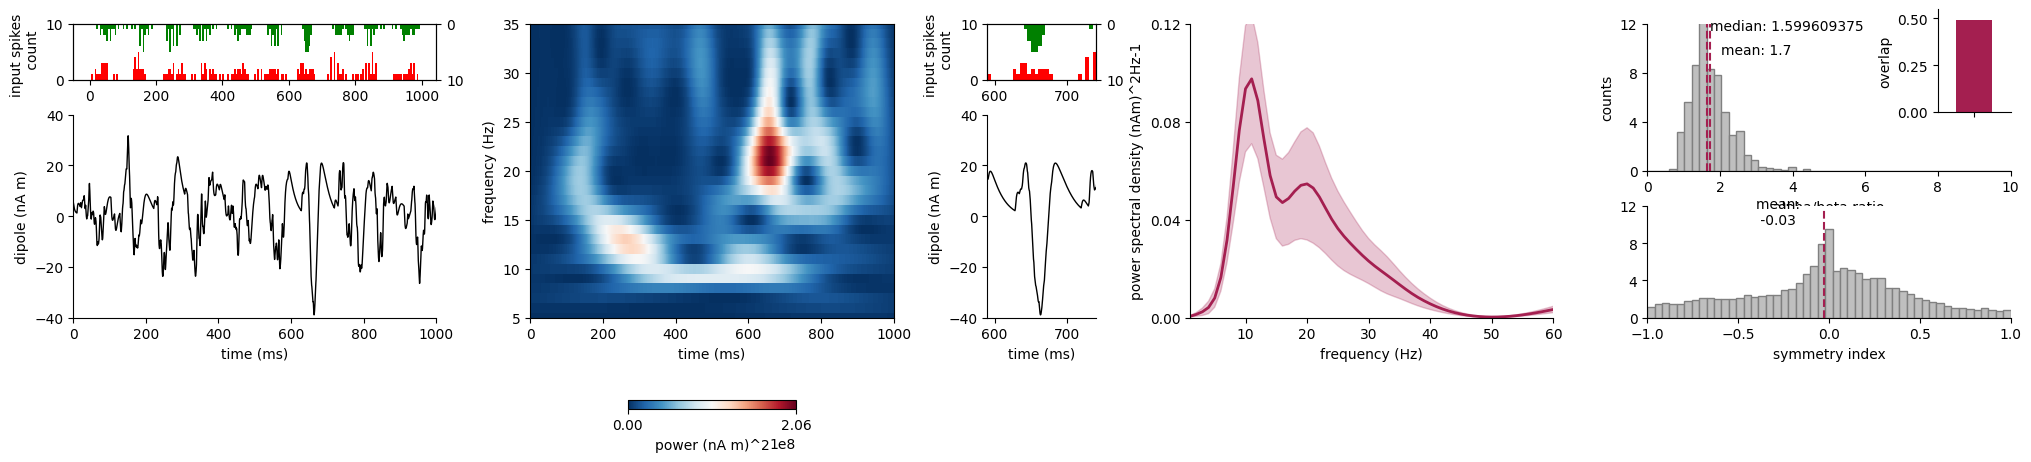

In [8]:
fig = plt.figure(figsize=(25,5))
gs= GridSpec(4, 5, width_ratios=[1,1,0.3,1,1], height_ratios=[0.5, 0.5, 1, 0.5], wspace=.3, hspace=0.5)
bins = np.arange(0, 1000, 5)  # histogram bins

ax = [None]*8
ax[0] = fig.add_subplot(gs[0,0])
ax[1] = fig.add_subplot(gs[1:3,0])
ax[2] = fig.add_subplot(gs[:3,1])
ax[3] = fig.add_subplot(gs[0,2])
ax[4] = fig.add_subplot(gs[1:3,2])
ax[5] = fig.add_subplot(gs[:3,3])
ax[6] = fig.add_subplot(gs[:2,4])
ax[7] = fig.add_subplot(gs[2:3,4])
cax = fig.add_subplot(gs[3,1])
#fig.tight_layout()
# fig.canvas.draw()

spike_prox = np.array(net.cell_response.spike_times_by_type['prox'][0]).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['dist'][0]).reshape(-1,1)

for i in [0, 3]:
    ax[i].hist(spike_prox, bins, color='r')
    ax[i].set_ylim([0, 10])
    ax[i].set_yticks([0, 10])

    ax1tw = ax[i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 10])
    ax1tw.set_yticks([0, 10])
    ax1tw.invert_yaxis()
    ax[i].set_ylabel('input spikes \n count')

ax[1].plot(dpl[0].times, dpl[0].data['agg'], color='k', linewidth=1.)
ax[1].set_yticks([-40, -20, 0, 20, 40])

ax[1].set_xlim([0, 1000])
ax[1].spines['top'].set_visible(False)
ax[1].spines['right'].set_visible(False)
ax[1].set_ylabel('dipole (nA m)')
ax[1].set_ylim([-40, 40])

f, tfr = compute_tfr([dpl[0]])

im = ax[2].pcolormesh(dpl[0].times, f, tfr[0], cmap='RdBu_r', vmin=0, vmax=tfr.max())
# Get the position of ax[3] in figure coordinates
pos = ax[2].get_position()
# Create a new axes for the colorbar just to the right of ax[3]
cb = plt.colorbar(im, ax=cax, orientation='horizontal')
cb.set_ticks([0, tfr.max()])
ax[2].set_ylim([5, 35])
ax[2].set_ylabel('frequency (Hz)')
cax.set_axis_off()
cb.set_label('power (nA m)^2')
ax[4].plot(dpl[0].times, dpl[0].data['agg'], color='k', linewidth=1.)
ax[4].set_xlim([590, 740])
ax[4].spines['top'].set_visible(False)
ax[4].spines['right'].set_visible(False)
ax[4].set_ylabel('dipole (nA m)')
ax[4].set_ylim([-40, 40])
ax[4].set_yticks([-40, -20, 0, 20, 40])
ax[4].set_xlim([590, 740])
ax[3].set_xlim([590, 740])


for i in [1,2,4]:
    ax[i].set_xlabel('time (ms)')



f, psd = compute_psd(params, dpl)

ax[5].plot(f[0], psd.mean(axis=0),color='#a41f50', linewidth=2)
ax[5].set_xlim([1, 60])
ax[5].fill_between(f[0], psd.mean(axis=0)-psd.std(axis=0), psd.mean(axis=0)+psd.std(axis=0),color='#a41f50', alpha=0.25)
ax[5].spines['top'].set_visible(False)
ax[5].spines['right'].set_visible(False)
ax[5].set_ylabel('power spectral density (nAm)^2Hz-1')
ax[5].set_ylim([0, 0.12])
ax[5].set_yticks([0, 0.04, 0.08, 0.12])
ax[5].set_xlabel('frequency (Hz)')

abr = np.concatenate(sim.alpha_beta_ratio.values)
mabr = np.round(np.mean(abr),1).astype('float16')
medabr = np.round(np.median(abr),1).astype('float16')
ax[6].hist(abr, bins=np.linspace(0, 10, 50), facecolor=[0.75, 0.75, 0.75], edgecolor=[0.5, 0.5, 0.5]);
ax[6].vlines(np.mean(abr), ymin=0, ymax=1200, color='#a41f50', linestyle='--')
ax[6].vlines(np.median(abr), ymin=0, ymax=1200, color='#a41f50', linestyle='--')
ax[6].text(np.mean(abr)+0.3, 950, f'mean: {mabr:0.1f}', color='k')
ax[6].text(np.median(abr)+0.1, 1150, f'median: {medabr}', color='k')
ax[6].set_xlabel('alpha/beta ratio')
ax[6].spines['top'].set_visible(False)
ax[6].spines['right'].set_visible(False)
ax[6].set_ylim([0, 1200])
ax[6].set_yticks([0, 400, 800, 1200])
ax[6].set_xlim([0, 10])
ax92 = ax[6].inset_axes([.8, 0.4, 0.2, .7])
ax92.bar(x=1, height=np.mean(sim.prob_overlap), width=0.5, color='#a41f50')
ax92.set_xlim([0.5, 1.5])
ax92.set_xticks([1])
ax92.set_xticklabels([])
ax92.set_ylim([0, 0.55])
ax92.set_yticks([0, 0.25, 0.5])
ax92.set_ylabel('overlap')
ax92.spines['top'].set_visible(False)
ax92.spines['right'].set_visible(False)
ax[6].set_ylabel('counts')
ax[6].set_yticklabels([0, 4, 8, 12])

sid = np.concatenate(sim.symmetry_index.values)
ax[7].hist(sid, bins=np.linspace(-1,1,50), facecolor=[0.75, 0.75, 0.75], edgecolor=[0.5, 0.5, 0.5]);
ax[7].vlines(np.mean(sid), ymin=0, ymax=1150, linewidth=1.5, color='#a41f50', linestyle='--')
ax[7].text(-0.4, 1000, f'mean: \n {np.round(np.mean(sid),2)}')
ax[7].set_xlabel('symmetry index')
ax[7].spines['top'].set_visible(False)
ax[7].spines['right'].set_visible(False)
ax[7].set_ylim([0, 1200])
ax[7].set_yticks(np.arange(0, 1201, 400))
ax[7].set_xlim([-1, 1])
ax[7].set_xticks([-1, -0.5, 0, 0.5, 1])
ax[7].set_yticklabels([0, 4, 8, 12])
fig.savefig(op.join(pathfig, 'alpha_beta_sim.pdf'))
fig.savefig(op.join(pathfig, 'alpha_beta_sim.png'))

In [9]:
net_single_trl = net.copy()
del net
net_single_trl.set_cell_positions(inplane_distance=30)
depths = list(list(range(-500,2200,100)))
electrode_pos = [(135, 135, dep) for dep in depths]
net_single_trl.add_electrode_array('probe1', electrode_pos)
with MPIBackend(n_procs=20, mpi_cmd='mpiexec'):
    dpl = simulate_dipole(net_single_trl, tstop=1000, n_trials=1, bsl_cor='duecker')

/oscar/home/kduecker/oscar-install/hnn-core/hnn_core/parallel_backends.py:940: UserWarning: Number of requested MPI processes exceeds available cores. Enabling MPI oversubscription automatically.
  warn(


MPI will run 1 trial(s) sequentially by distributing network neurons over 20 processes.
numprocs=20
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-core/hnn_core/mod/x86_64/libnrnmech.so
Loading custom mechanism files from /oscar/home/kduecker/oscar-install/hnn-c

In [10]:
lfp = net_single_trl.rec_arrays['probe1'][0].voltages[0]

from hnn_core.extracellular import _get_laminar_z_coords, calculate_csd2d
from scipy.interpolate import RectBivariateSpline
# from hnn_core.utils import smooth_waveform
contact_labels, delta = _get_laminar_z_coords(net_single_trl.rec_arrays['probe1'][0].positions)
contact_l_cm = contact_labels[::2]/1000
yticklabels = np.abs(np.round(contact_l_cm-contact_l_cm.max(),1))
yticks = np.linspace(contact_labels[0], contact_labels[-1], len(yticklabels))


# for i in range(lfp.shape[0]):
#     lfp[i] = smooth_waveform(lfp[i], smooth_win, net_single_trl.rec_arrays['probe1'].sfreq)
    
csd = calculate_csd2d(lfp, delta=delta)

# create interpolation function
interp_data = RectBivariateSpline(net_single_trl.cell_response.times, contact_labels, csd.T)

# increase number of contacts
new_depths = np.linspace(
    contact_labels[0],
    contact_labels[-1],
    contact_labels[-1] - contact_labels[0],
)
# interpolate
csd_int = interp_data(net_single_trl.cell_response.times, new_depths).T

voltage_offset = 500

trace_offset = np.arange(lfp.shape[0])[:, np.newaxis]* voltage_offset
trace_offset_2d = np.tile(trace_offset, (1, lfp.shape[1]))


yticklabels = np.abs(np.round(contact_l_cm-contact_l_cm.max(),1))
yticks = np.linspace(contact_labels[0], contact_labels[-1], len(yticklabels))

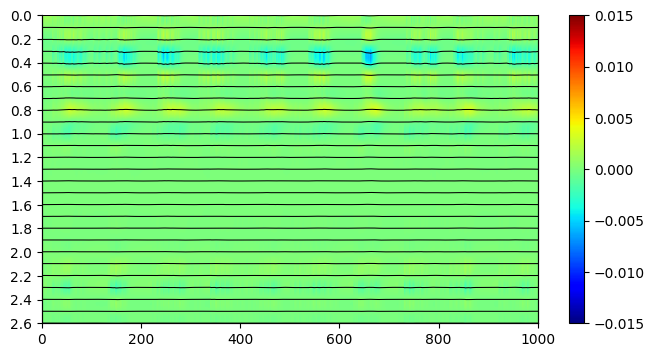

In [11]:
fig, ax = plt.subplots(figsize=(8,4))
im = ax.pcolormesh(net_single_trl.cell_response.times, new_depths, csd_int, cmap='jet', shading="auto", rasterized=True, vmin=-0.015, vmax=0.015)

ax.set_yticks(yticks)
ax.set_yticklabels(yticklabels)
ax.spines['top'].set_visible(False)
ax0tw = ax.twinx()
ax0tw.plot(net_single_trl.cell_response.times, (lfp+trace_offset_2d).T, color='k', linewidth=0.75);
ax0tw.set_yticks(trace_offset[::2].reshape(-1,))                      # make sure that ylims are aligned
ax0tw.set_yticks([])
ax0tw.set_ylim(trace_offset[0], trace_offset[::2][-1])
ax0tw.spines['top'].set_visible(False)
cb = plt.colorbar(im)
#cb.set_ticks([-0.1, 0, 0.1])


In [12]:
fig.savefig('mu_csd_lfp.pdf', dpi=600)

## Compare to data

In [13]:
class Dipole:

    def __init__(self, mat_data): 

        self.data = dict()
        self.data['agg'] = mat_data
        self.times = np.linspace(0, 1, mat_data.shape[0])
        self.nave = 1
        self.scale_applied = 1  # for visualisation
        self.sfreq = mat_data.shape[0]

In [ ]:
#for s in np.arange(1,11):
params['nfft']=None
data = sio.loadmat(f'{data_pth}/prestim_humandetection_600hzMEG_subject{1}.mat')
n_trials = len(data['prestim_raw_yes_no'])
subj1_dpls = [None]* n_trials
for trl in range(n_trials):
    data_dpl = Dipole(data['prestim_raw_yes_no'][trl]*1e9)          # convert to nA
    subj1_dpls[trl] = data_dpl

s_idx = np.zeros((n_trials,), dtype=object)
for i, dip in enumerate(subj_dpls):
    s, ff = compute_symmetry_index(dip, lowcut=7, highcut=29, prominence=1e-8)
    s_idx[i] = s

ab_ratio, alpha_power, beta_power, prob_overlap = alpha_beta_ratio(subj1_dpls, dpl_type='data')

povl = np.zeros(10,)
povl[0] = prob_overlap

f, psd_subj = compute_psd(params, subj1_dpls)
psd_all_subj = np.zeros((10, f.shape[1]))
psd_all_subj[0] = psd_subj.mean(axis=0)

NameError: name 'subj_dpls' is not defined

In [170]:
for si in np.arange(2,11):
    data = sio.loadmat(f'{data_pth}/prestim_humandetection_600hzMEG_subject{si}.mat')
    n_trials = len(data['prestim_raw_yes_no'])
    subj_dpls = [None]* n_trials
    for trl in range(n_trials):
        data_dpl = Dipole(data['prestim_raw_yes_no'][trl]*1e9)
        subj_dpls[trl] = data_dpl

    sid = np.zeros((n_trials,), dtype=object)
    for i, dip in enumerate(subj_dpls):
        s, ff = compute_symmetry_index(dip, lowcut=7, highcut=29, prominence=1e-8)
        sid[i] = s

    s_idx = np.concatenate((s_idx,sid))

    abr, _, _, prob_overlap = alpha_beta_ratio(subj_dpls, dpl_type='data')

    ab_ratio = np.concatenate((ab_ratio, abr))
    povl[int(si-1)] = prob_overlap

    _, psd_subj = compute_psd(params, subj_dpls)

    psd_all_subj[si-1] = psd_subj.mean(axis=0)

In [ ]:
fig = plt.figure(figsize=(16,8))
gs= GridSpec(2, 4, width_ratios=[1,1,0.3, 0.3], height_ratios=[1, 1], wspace=.3, hspace=0.25)
bins = np.arange(0, 1000, 5)  # histogram bins

ax = [None]*7

ax[0] = fig.add_subplot(gs[0,0])
ax[1] = fig.add_subplot(gs[0,1])
ax[2] = fig.add_subplot(gs[0,2])
ax[3] = fig.add_subplot(gs[0,3])

ax[4] = fig.add_subplot(gs[1,0])
ax[5] = fig.add_subplot(gs[1,1])
ax[6] = fig.add_subplot(gs[1,2:])

ax[0].plot(subj1_dpls[0].times*1000, subj1_dpls[90].data['agg'], color='k', linewidth=1.)
ax[0].set_yticks([-50, -25, 0, 25, 50])

ax[0].set_xlim([0, 1000])
ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)
ax[0].set_ylabel('dipole (nA m)')
ax[0].set_ylim([-50, 50])

freq, tfr = compute_tfr([subj1_dpls[90]])
im = ax[1].pcolormesh(subj_dpls[1].times*1000, freq, tfr[0], cmap='RdBu_r', vmin=0, vmax=tfr.max())
# Get the position of ax[3] in figure coordinates
pos = ax[1].get_position()
# Create a new axes for the colorbar just to the right of ax[3]
cax = fig.add_axes([pos.x1 + 0.0025, pos.y0, 0.005, pos.height])
#cax.set_axis_off()
cb = plt.colorbar(im, cax=cax)
cb.set_ticks([0, tfr.max()])

ax[1].set_ylim([5, 35])
ax[1].set_ylabel('frequency (Hz)')
ax[2].plot(subj1_dpls[0].times*1000, subj1_dpls[90].data['agg'], color='k', linewidth=1.)
ax[2].set_xlim([500, 650])
ax[2].spines['top'].set_visible(False)
ax[2].spines['right'].set_visible(False)
ax[2].set_ylabel('dipole (nA m)')
ax[2].set_ylim([-50, 50])
ax[2].set_yticks([-50, -25, 0, 25, 50])

ax[3].pcolormesh(subj1_dpls[0].times*1000, freq, tfr[0], cmap='RdBu_r', vmin=0, vmax=tfr.max())
ax[3].set_ylim([5, 35])
ax[3].set_ylabel('frequency (Hz)')
ax[3].set_xlim([500, 650])

for i in np.arange(4):
    ax[i].set_xlabel('time (ms)')

ax[4].plot(f[0], psd_all_subj.mean(axis=0),color='#228c22', linewidth=2)
ax[4].set_xlim([1, 60])
ax[4].fill_between(f[0], psd_all_subj.mean(axis=0)-psd_all_subj.std(axis=0), psd_all_subj.mean(axis=0)+psd_all_subj.std(axis=0),color='#4E664F', alpha=0.25)
ax[4].spines['top'].set_visible(False)
ax[4].spines['right'].set_visible(False)
ax[4].set_ylabel('power spectral density (nAm)^2Hz-1')
ax[4].set_ylim([0, 1.6])
ax[4].set_yticks([0, 0.4, 0.8, 1.2, 1.6])
ax[4].set_xlabel('frequency (Hz)')

abr = np.concatenate(ab_ratio)

ax[5].hist(abr, bins=np.linspace(0, 10, 50), facecolor=[0.75, 0.75, 0.75], edgecolor=[0.5, 0.5, 0.5]);
ax[5].vlines(np.mean(abr), ymin=0, ymax=2500, color='#228c22', linestyle='--')
ax[5].vlines(np.median(abr), ymin=0, ymax=2500, color='#228c22', linestyle='--')
ax[5].text(np.mean(abr)+0.3, 2200, f'mean: {np.mean(abr):0.1f}', color='k')
ax[5].text(np.median(abr)+0.1, 2500, f'median: {np.median(abr)}', color='k')
ax[5].set_xlabel('alpha/beta ratio')
ax[5].spines['top'].set_visible(False)
ax[5].spines['right'].set_visible(False)
ax[5].set_ylim([0, 2500])
ax[5].set_yticks(np.arange(0,2501,500))
ax[5].set_xlim([0, 10])
ax92 = ax[5].inset_axes([.75, 0.35, 0.2, .6])
ax92.bar(x=1, height=np.mean(povl), width=0.5, color='#228c22', xerr=np.std(povl))
ax92.set_xlim([0.5, 1.5])
ax92.set_xticks([1])
ax92.set_xticklabels([])
ax92.set_ylim([0, 0.55])
ax92.set_yticks([0, 0.25, 0.5])
ax92.set_ylabel('prob. overlap')
ax92.spines['top'].set_visible(False)
ax92.spines['right'].set_visible(False)
ax[5].set_ylabel('counts')

sid = np.concatenate(s_idx)
ax[6].hist(sid, bins=np.linspace(-1,1,50), facecolor=[0.75, 0.75, 0.75], edgecolor=[0.5, 0.5, 0.5]);
ax[6].vlines(np.mean(sid), ymin=0, ymax=4000, linewidth=1.5, color='#228c22', linestyle='--')
ax[6].text(-0.4, 3500, f'mean: \n {np.round(np.mean(sid),2)}')
ax[6].set_xlabel('symmetry index')
ax[6].spines['top'].set_visible(False)
ax[6].spines['right'].set_visible(False)

ax[6].set_xlim([-1, 1])
ax[6].set_yticks(np.arange(0,4001,1000))

fig.savefig(op.join(pathfig, 'alpha_beta_data.pdf'))
fig.savefig(op.join(pathfig, 'alpha_beta_data.png'))

In [ ]:
fig = plt.figure(figsize=(25,5))
gs= GridSpec(3, 5, width_ratios=[1,1,0.3,1,1], height_ratios=[0.5, 0.5, 0.3], wspace=.3, hspace=0.5)
bins = np.arange(0, 1000, 5)  # histogram bins

ax = [None]*6

ax[0] = fig.add_subplot(gs[:2,0])
ax[1] = fig.add_subplot(gs[:2,1])
ax[2] = fig.add_subplot(gs[:2,2])
ax[3] = fig.add_subplot(gs[:2,3])

ax[4] = fig.add_subplot(gs[0,4])
ax[5] = fig.add_subplot(gs[1,4])
cax = fig.add_subplot(gs[2,1])

ax[0].plot(subj1_dpls[0].times*1000, subj1_dpls[90].data['agg'], color='k', linewidth=1.)
ax[0].set_yticks([-50, -25, 0, 25, 50])

ax[0].set_xlim([0, 1000])
ax[0].spines['top'].set_visible(False)
ax[0].spines['right'].set_visible(False)
ax[0].set_ylabel('dipole (nA m)')
ax[0].set_ylim([-50, 50])

freq, tfr = compute_tfr([subj1_dpls[90]])
im = ax[1].pcolormesh(subj_dpls[1].times*1000, freq, tfr[0], cmap='RdBu_r', vmin=0, vmax=tfr.max())
# Get the position of ax[3] in figure coordinates
pos = ax[1].get_position()
# Create a new axes for the colorbar just to the right of ax[3]
#cax = fig.add_axes([pos.x1 - pos.width+pos.width*0.4, pos.y0-0.2, pos.width*0.6, 0.035])
cb = plt.colorbar(im, ax=cax, orientation='horizontal')
cb.set_ticks([0, tfr.max()])
cb.set_label('power (nA m)^2')
cax.set_axis_off()


ax[1].set_ylim([5, 35])
ax[1].set_ylabel('frequency (Hz)')
ax[2].plot(subj1_dpls[0].times*1000, subj1_dpls[90].data['agg'], color='k', linewidth=1.)
ax[2].set_xlim([500, 650])
ax[2].spines['top'].set_visible(False)
ax[2].spines['right'].set_visible(False)
ax[2].set_ylabel('dipole (nA m)')
ax[2].set_ylim([-50, 50])
ax[2].set_yticks([-50, -25, 0, 25, 50])

for i in np.arange(3):
    ax[i].set_xlabel('time (ms)')

ax[3].plot(f[0], psd_all_subj.mean(axis=0),color='#228c22', linewidth=2)
ax[3].set_xlim([1, 60])
ax[3].fill_between(f[0], psd_all_subj.mean(axis=0)-psd_all_subj.std(axis=0), psd_all_subj.mean(axis=0)+psd_all_subj.std(axis=0),color='#4E664F', alpha=0.25)
ax[3].spines['top'].set_visible(False)
ax[3].spines['right'].set_visible(False)
ax[3].set_ylabel('power spectral density (nAm)^2Hz-1')
ax[3].set_ylim([0, 1.6])
ax[3].set_yticks([0, 0.4, 0.8, 1.2, 1.6])
ax[3].set_xlabel('frequency (Hz)')

abr = np.concatenate(ab_ratio)

ax[4].hist(abr, bins=np.linspace(0, 10, 50), facecolor=[0.75, 0.75, 0.75], edgecolor=[0.5, 0.5, 0.5]);
ax[4].vlines(np.mean(abr), ymin=0, ymax=2500, color='#228c22', linestyle='--')
ax[4].vlines(np.median(abr), ymin=0, ymax=2500, color='#228c22', linestyle='--')
ax[4].text(np.mean(abr)+0.3, 2200, f'mean: {np.mean(abr):0.1f}', color='k')
ax[4].text(np.median(abr)+0.1, 2500, f'median: {np.median(abr):0.1f}', color='k')
ax[4].set_xlabel('alpha/beta ratio')
ax[4].spines['top'].set_visible(False)
ax[4].spines['right'].set_visible(False)
ax[4].set_ylim([0, 2500])
ax[4].set_yticks(np.arange(0,2501,1000))
ax[4].set_yticklabels(np.arange(0,25,10))
ax[4].set_xlim([0, 10])
ax92 = ax[4].inset_axes([.8, 0.4, 0.2, .7])
ax92.bar(x=1, height=np.mean(povl), width=0.5, color='#228c22', xerr=np.std(povl))
ax92.set_xlim([0.5, 1.5])
ax92.set_xticks([1])
ax92.set_xticklabels([])
ax92.set_ylim([0, 0.62])
ax92.set_yticks([0, 0.6])
ax92.set_ylabel('overlap')
ax92.spines['top'].set_visible(False)
ax92.spines['right'].set_visible(False)
ax[4].set_ylabel('counts')

sid = np.concatenate(s_idx)
ax[5].hist(sid, bins=np.linspace(-1,1,50), facecolor=[0.75, 0.75, 0.75], edgecolor=[0.5, 0.5, 0.5]);
ax[5].vlines(np.mean(sid), ymin=0, ymax=4000, linewidth=1.5, color='#228c22', linestyle='--')
ax[5].text(-0.4, 3500, f'mean: \n {np.round(np.mean(sid),2)}')
ax[5].set_xlabel('symmetry index')
ax[5].spines['top'].set_visible(False)
ax[5].spines['right'].set_visible(False)

ax[5].set_xlim([-1, 1])
ax[5].set_xticks([-1, -0.5, 0, 0.5, 1])
ax[5].set_yticks(np.arange(0,4001,1000))
ax[5].set_yticklabels(np.arange(0,41,10))

fig.savefig(op.join(pathfig, 'alpha_beta_data.pdf'))
fig.savefig(op.join(pathfig, 'alpha_beta_data.png'))

In [ ]:
povl.mean()